In [35]:
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math

In [3]:
models = ["tropical", "tropical_v2", "transformer", "edge_transformer", "gnn"]

evaluation_types = ["id_new", "ood_size", "value_ood", "wood", "external"]

training_set = "onein_reps100"

dfs = []

for eval_type in evaluation_types:
    
    for model in models:
        
        filename = (f"evaluation_results_{model}_shortest_path_{eval_type}_{training_set}_candidate4.csv")
        
        df = pd.read_csv(filename)

        # Add identifiers
        df["model_type"] = model
        df["evaluation_type"] = eval_type
        df["training_set"] = training_set

        dfs.append(df)

# Combine all 25 files
df_all = pd.concat(dfs, ignore_index=True)

In [197]:
models = ["tropical", "tropical_v2", "transformer", "edge_transformer", "gnn"]

evaluation_types = ["id_new", "ood_size", "value_ood"]

training_set = "onein_reps100"

dfs = []

for eval_type in evaluation_types:
    
    for model in models:
        
        filename = (f"evaluation_results_{model}_shortest_path_{eval_type}_{training_set}_eval_filtered.csv")
        
        df = pd.read_csv(filename)

        # Add identifiers
        df["model_type"] = model
        df["evaluation_type"] = eval_type
        df["training_set"] = training_set

        dfs.append(df)

# Combine all 25 files
df_all = pd.concat(dfs, ignore_index=True)

In [4]:
df_all.to_csv("evaluation_results_onein_reps100_all.csv", index=False)

In [199]:
df_all.to_csv("evaluation_results_onein_filtered_eval.csv", index=False)

In [7]:
pd.set_option('display.max_columns',None)

In [9]:
df_trop = pd.read_csv('training_log_tropical_shortest_path_onein_reps100.csv')
df_trop_v2 = pd.read_csv('training_log_tropical_v2_shortest_path_onein_reps100.csv')
df_trans = pd.read_csv('training_log_transformer_shortest_path_onein_reps100.csv')
df_edge = pd.read_csv('training_log_edge_transformer_shortest_path_onein_reps100.csv')
df_gnn = pd.read_csv('training_log_gnn_shortest_path_onein_reps100.csv')

In [11]:
df_trop["model_type"] = "tropical"
df_trop_v2["model_type"] = "tropical_v2"
df_trans["model_type"] = "transformer"
df_edge["model_type"] = "edge_transformer"
df_gnn["model_type"] = "gnn"

df_all = pd.concat([df_trop, df_trop_v2, df_trans, df_edge, df_gnn], ignore_index=True)

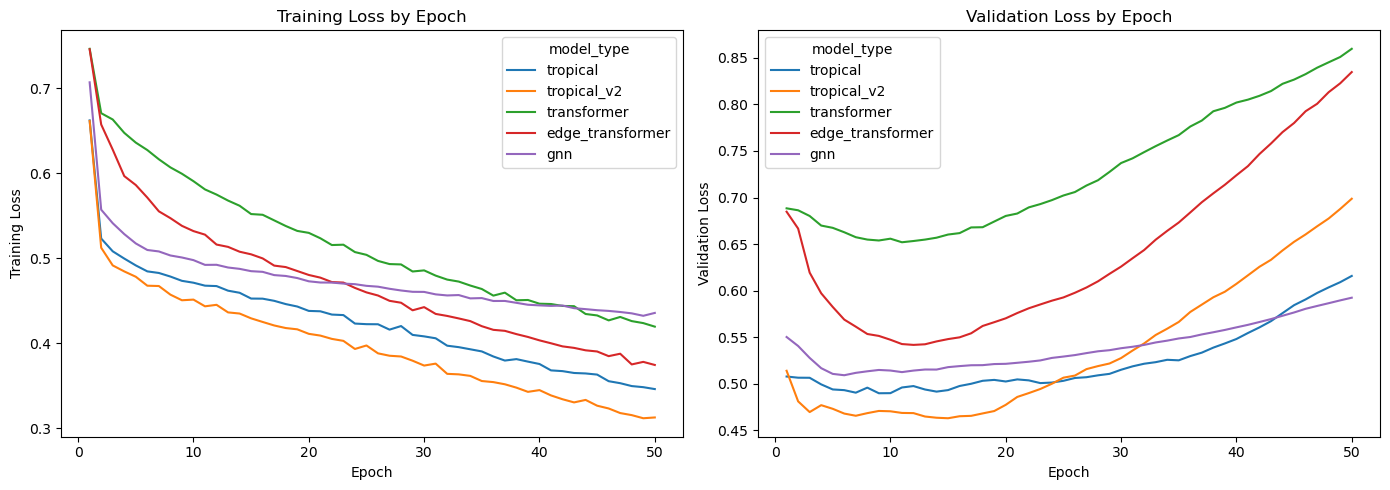

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)

sns.lineplot(
    data=df_all,
    x="epoch",
    y="train_loss",
    hue="model_type",
    ax=axes[0]
)

axes[0].set_title("Training Loss by Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Training Loss")

sns.lineplot(
    data=df_all,
    x="epoch",
    y="val_loss",
    hue="model_type",
    ax=axes[1]
)

axes[1].set_title("Validation Loss by Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation Loss")

plt.tight_layout()
plt.show()

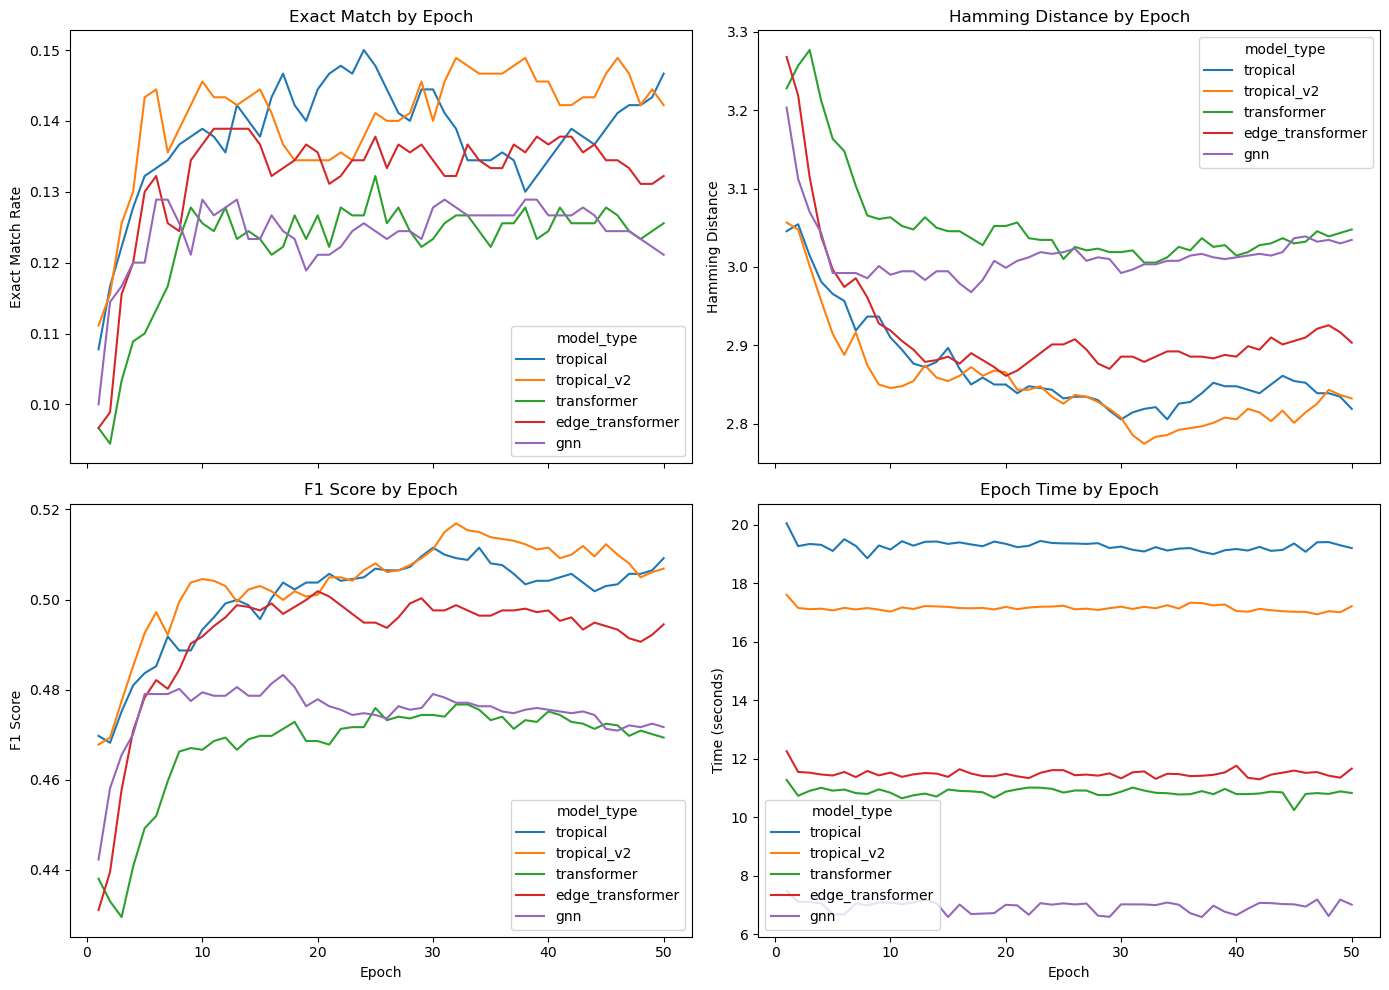

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True)

sns.lineplot(
    data=df_all,
    x="epoch",
    y="exact_match",
    hue="model_type",
    ax=axes[0, 0]
)
axes[0, 0].set_title("Exact Match by Epoch")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Exact Match Rate")

sns.lineplot(
    data=df_all,
    x="epoch",
    y="hamming",
    hue="model_type",
    ax=axes[0, 1]
)
axes[0, 1].set_title("Hamming Distance by Epoch")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Hamming Distance")

sns.lineplot(
    data=df_all,
    x="epoch",
    y="f1",
    hue="model_type",
    ax=axes[1, 0]
)
axes[1, 0].set_title("F1 Score by Epoch")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("F1 Score")

sns.lineplot(
    data=df_all,
    x="epoch",
    y="epoch_time_seconds",
    hue="model_type",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Epoch Time by Epoch")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("Time (seconds)")

plt.tight_layout()
plt.show()

## Unfiltered ID Evaluation Results

In [68]:
df_tropical_eval = pd.read_csv('evaluation_results_tropical_shortest_path_id_new_onein_reps100_candidate4.csv')
df_tropical_v2_eval = pd.read_csv('evaluation_results_tropical_v2_shortest_path_id_new_onein_reps100_candidate4.csv')
df_transformer_eval = pd.read_csv('evaluation_results_transformer_shortest_path_id_new_onein_reps100_candidate4.csv')
df_edge_eval = pd.read_csv('evaluation_results_edge_transformer_shortest_path_id_new_onein_reps100_candidate4.csv')
df_gnn_eval = pd.read_csv('evaluation_results_gnn_shortest_path_id_new_onein_reps100_candidate4.csv')

## Unfiltered ID Filtered Evaluation Results

In [103]:
df_tropical_eval = pd.read_csv('evaluation_results_tropical_shortest_path_id_new_onein_reps100_eval_filtered.csv')
df_tropical_v2_eval = pd.read_csv('evaluation_results_tropical_v2_shortest_path_id_new_onein_reps100_eval_filtered.csv')
df_transformer_eval = pd.read_csv('evaluation_results_transformer_shortest_path_id_new_onein_reps100_eval_filtered.csv')
df_edge_eval = pd.read_csv('evaluation_results_edge_transformer_shortest_path_id_new_onein_reps100_eval_filtered.csv')
df_gnn_eval = pd.read_csv('evaluation_results_gnn_shortest_path_id_new_onein_reps100_eval_filtered.csv')

## Unfiltered OOD Size Evaluation Results

In [117]:
df_tropical_eval = pd.read_csv('evaluation_results_tropical_shortest_path_ood_size_onein_reps100_candidate4.csv')
df_tropical_v2_eval = pd.read_csv('evaluation_results_tropical_v2_shortest_path_ood_size_onein_reps100_candidate4.csv')
df_transformer_eval = pd.read_csv('evaluation_results_transformer_shortest_path_ood_size_onein_reps100_candidate4.csv')
df_edge_eval = pd.read_csv('evaluation_results_edge_transformer_shortest_path_ood_size_onein_reps100_candidate4.csv')
df_gnn_eval = pd.read_csv('evaluation_results_gnn_shortest_path_ood_size_onein_reps100_candidate4.csv')

## Unfiltered OOD Size Filtered Evaluation Results

In [131]:
df_tropical_eval = pd.read_csv('evaluation_results_tropical_shortest_path_ood_size_onein_reps100_eval_filtered.csv')
df_tropical_v2_eval = pd.read_csv('evaluation_results_tropical_v2_shortest_path_ood_size_onein_reps100_eval_filtered.csv')
df_transformer_eval = pd.read_csv('evaluation_results_transformer_shortest_path_ood_size_onein_reps100_eval_filtered.csv')
df_edge_eval = pd.read_csv('evaluation_results_edge_transformer_shortest_path_ood_size_onein_reps100_eval_filtered.csv')
df_gnn_eval = pd.read_csv('evaluation_results_gnn_shortest_path_ood_size_onein_reps100_eval_filtered.csv')

## Unfiltered OOD Value Evaluation Results

In [145]:
df_tropical_eval = pd.read_csv('evaluation_results_tropical_shortest_path_value_ood_onein_reps100_candidate4.csv')
df_tropical_v2_eval = pd.read_csv('evaluation_results_tropical_v2_shortest_path_value_ood_onein_reps100_candidate4.csv')
df_transformer_eval = pd.read_csv('evaluation_results_transformer_shortest_path_value_ood_onein_reps100_candidate4.csv')
df_edge_eval = pd.read_csv('evaluation_results_edge_transformer_shortest_path_value_ood_onein_reps100_candidate4.csv')
df_gnn_eval = pd.read_csv('evaluation_results_gnn_shortest_path_value_ood_onein_reps100_candidate4.csv')

## Unfiltered OOD Value Filtered Evaluation Results

In [161]:
df_tropical_eval = pd.read_csv('evaluation_results_tropical_shortest_path_value_ood_onein_reps100_eval_filtered.csv')
df_tropical_v2_eval = pd.read_csv('evaluation_results_tropical_v2_shortest_path_value_ood_onein_reps100_eval_filtered.csv')
df_transformer_eval = pd.read_csv('evaluation_results_transformer_shortest_path_value_ood_onein_reps100_eval_filtered.csv')
df_edge_eval = pd.read_csv('evaluation_results_edge_transformer_shortest_path_value_ood_onein_reps100_eval_filtered.csv')
df_gnn_eval = pd.read_csv('evaluation_results_gnn_shortest_path_value_ood_onein_reps100_eval_filtered.csv')

## Wood Evaluation Results

In [201]:
df_tropical_eval = pd.read_csv('evaluation_results_tropical_shortest_path_wood_onein_reps100_candidate4.csv')
df_tropical_v2_eval = pd.read_csv('evaluation_results_tropical_v2_shortest_path_wood_onein_reps100_candidate4.csv')
df_transformer_eval = pd.read_csv('evaluation_results_transformer_shortest_path_wood_onein_reps100_candidate4.csv')
df_edge_eval = pd.read_csv('evaluation_results_edge_transformer_shortest_path_wood_onein_reps100_candidate4.csv')
df_gnn_eval = pd.read_csv('evaluation_results_gnn_shortest_path_wood_onein_reps100_candidate4.csv')

## External Evaluation Results

In [209]:
df_tropical_eval = pd.read_csv('evaluation_results_tropical_shortest_path_external_onein_reps100_candidate4.csv')
df_tropical_v2_eval = pd.read_csv('evaluation_results_tropical_v2_shortest_path_external_onein_reps100_candidate4.csv')
df_transformer_eval = pd.read_csv('evaluation_results_transformer_shortest_path_external_onein_reps100_candidate4.csv')
df_edge_eval = pd.read_csv('evaluation_results_edge_transformer_shortest_path_external_onein_reps100_candidate4.csv')
df_gnn_eval = pd.read_csv('evaluation_results_gnn_shortest_path_external_onein_reps100_candidate4.csv')

In [211]:
df_tropical_eval["model_type"] = "tropical"
df_tropical_v2_eval["model_type"] = "tropical_v2"
df_transformer_eval["model_type"] = "transformer"
df_gnn_eval["model_type"] = "gnn"
df_edge_eval["model_type"] = "edge_transformer"


df_all_eval = pd.concat([df_gnn_eval, df_edge_eval, df_tropical_v2_eval],ignore_index=True)

df_all_eval.head()

,model_type,problem_type,eval_mode,wood_problem,wood_rows,wood_cols,network_name,graph_seed,n_nodes,n_edges,density,replication,source,sink,source_original,sink_original,attack_limit,optimal_objective,predicted_objective,objective_gap,hamming_distance,exact_match,num_correct_edges,num_predicted_attacks,num_optimal_attacks,mip_solve_time,mip_total_time,inference_time,candidate_objective,candidate_objective_gap,candidate_pool_size,num_candidates,candidate_search_time,hybrid_total_time,candidate_exact_match,candidate_hamming_distance,candidate_correct_edges
0,gnn,shortest_path,external,NaN,NaN,NaN,rail_road_transportation_network,NaN,1054,3250,3.083491,NaN,0,5,1,6,1,789.978254,694.054024,0.121426,2,0,0,1,1,3.227064,3.403401,0.156491,694.054024,0.121426,5,5,0.041295,0.197785,0,2,0
1,gnn,shortest_path,external,NaN,NaN,NaN,rail_road_transportation_network,NaN,1054,3250,3.083491,NaN,0,6,1,7,1,280.083703,184.159473,0.342484,2,0,0,1,1,3.384331,3.582394,0.001922,184.159473,0.342484,5,5,0.025145,0.027067,0,2,0
2,gnn,shortest_path,external,NaN,NaN,NaN,rail_road_transportation_network,NaN,1054,3250,3.083491,NaN,0,7,1,8,1,255.830073,159.905843,0.374953,2,0,0,1,1,2.512488,2.702145,0.002145,159.905843,0.374953,5,5,0.025033,0.027178,0,2,0
3,gnn,shortest_path,external,NaN,NaN,NaN,rail_road_transportation_network,NaN,1054,3250,3.083491,NaN,0,8,1,9,1,256.580749,160.656519,0.373856,2,0,0,1,1,2.510386,2.735844,0.001944,160.656519,0.373856,5,5,0.024730,0.026674,0,2,0
4,gnn,shortest_path,external,NaN,NaN,NaN,rail_road_transportation_network,NaN,1054,3250,3.083491,NaN,0,974,1,1077,1,899.175041,803.250811,0.106680,2,0,0,1,1,3.774075,3.965521,0.002147,803.250811,0.106680,5,5,0.030175,0.032322,0,2,0


In [213]:
summary = (
    df_all_eval.groupby(["model_type", "density"])
    .agg(
        count=("objective_gap", "count"),

        # Direct model prediction
        objective_gap_avg=("objective_gap", "mean"),
        objective_gap_median=("objective_gap", "median"),
        objective_gap_std=("objective_gap", "std"),

        candidate_objective_gap_avg=("candidate_objective_gap", "mean"),
        candidate_objective_gap_median=("candidate_objective_gap", "median"),
        candidate_objective_gap_std=("candidate_objective_gap", "std"),
        exact_match_avg=("exact_match", "mean"),
        exact_match_std=("exact_match", "std"),

        candidate_exact_match_avg=("candidate_exact_match", "mean"),
        candidate_exact_match_std=("candidate_exact_match", "std"),

        hamming_distance_avg=("hamming_distance", "mean"),
        hamming_distance_std=("hamming_distance", "std"),

        candidate_hamming_distance_avg=("candidate_hamming_distance", "mean"),
        candidate_hamming_distance_std=("candidate_hamming_distance", "std"),

        inference_time_avg=("inference_time", "mean"),
        inference_time_std=("inference_time", "std"),

        hybrid_total_time_avg=("hybrid_total_time", "mean"),
        hybrid_total_time_std=("hybrid_total_time", "std"),

        mip_solve_time_avg=("mip_solve_time", "mean"),
        mip_solve_time_std=("mip_solve_time", "std"),

        candidate_correct_edges_avg=("candidate_correct_edges", "mean"),
        candidate_correct_edges_std=("candidate_correct_edges", "std"),

        candidate_search_time_avg=("candidate_search_time", "mean"),
        candidate_search_time_std=("candidate_search_time", "std"),

        candidate_pool_size_avg=("candidate_pool_size", "mean"),
        num_candidates_avg=("num_candidates", "mean"),


    )
    .reset_index()
)

summary

,model_type,density,count,objective_gap_avg,objective_gap_median,objective_gap_std,candidate_objective_gap_avg,candidate_objective_gap_median,candidate_objective_gap_std,exact_match_avg,exact_match_std,candidate_exact_match_avg,candidate_exact_match_std,hamming_distance_avg,hamming_distance_std,candidate_hamming_distance_avg,candidate_hamming_distance_std,inference_time_avg,inference_time_std,hybrid_total_time_avg,hybrid_total_time_std,mip_solve_time_avg,mip_solve_time_std,candidate_correct_edges_avg,candidate_correct_edges_std,candidate_search_time_avg,candidate_search_time_std,candidate_pool_size_avg,num_candidates_avg
0,edge_transformer,3.083491,150,0.439713,0.445041,0.195963,0.433111,0.444806,0.195748,0.0,0.0,0.000000,0.000000,5.986667,2.823646,5.920000,2.760021,0.011525,0.011303,0.322770,0.268591,4.932295,5.591604,0.040000,0.228212,0.311245,0.269285,7.0,50.2
1,gnn,3.083491,150,0.439967,0.446191,0.196532,0.439834,0.446191,0.196730,0.0,0.0,0.000000,0.000000,6.000000,2.837903,6.000000,2.837903,0.002983,0.012618,0.311739,0.269378,4.923632,5.575883,0.000000,0.000000,0.308756,0.270118,7.0,50.2
2,tropical_v2,3.083491,150,0.440334,0.446191,0.196107,0.429488,0.446191,0.210534,0.0,0.0,0.026667,0.161647,6.000000,2.837903,5.946667,2.930485,0.043298,0.053424,0.374283,0.274871,4.925784,5.590313,0.026667,0.161647,0.330984,0.274352,7.0,50.2


In [207]:
summary = (
    df_all_eval.groupby(["model_type", "attack_limit"])
    .agg(
        count=("objective_gap", "count"),

        # Direct model prediction
        objective_gap_avg=("objective_gap", "mean"),
        objective_gap_median=("objective_gap", "median"),
        objective_gap_std=("objective_gap", "std"),

        candidate_objective_gap_avg=("candidate_objective_gap", "mean"),
        candidate_objective_gap_median=("candidate_objective_gap", "median"),
        candidate_objective_gap_std=("candidate_objective_gap", "std"),
        
        #exact_match_avg=("exact_match", "mean"),
        #exact_match_std=("exact_match", "std"),

        #candidate_exact_match_avg=("candidate_exact_match", "mean"),
        #candidate_exact_match_std=("candidate_exact_match", "std"),

        hamming_distance_avg=("hamming_distance", "mean"),
        hamming_distance_std=("hamming_distance", "std"),

        candidate_hamming_distance_avg=("candidate_hamming_distance", "mean"),
        candidate_hamming_distance_std=("candidate_hamming_distance", "std"),

        inference_time_avg=("inference_time", "mean"),
        inference_time_std=("inference_time", "std"),

        hybrid_total_time_avg=("hybrid_total_time", "mean"),
        hybrid_total_time_std=("hybrid_total_time", "std"),

        mip_solve_time_avg=("mip_solve_time", "mean"),
        mip_solve_time_std=("mip_solve_time", "std"),

        #candidate_correct_edges_avg=("candidate_correct_edges", "mean"),
        #candidate_correct_edges_std=("candidate_correct_edges", "std"),

        #candidate_search_time_avg=("candidate_search_time", "mean"),
        #candidate_search_time_std=("candidate_search_time", "std"),

        #candidate_pool_size_avg=("candidate_pool_size", "mean"),
        #num_candidates_avg=("num_candidates", "mean"),


    )
    .reset_index()
)

summary

,model_type,attack_limit,count,objective_gap_avg,objective_gap_median,objective_gap_std,candidate_objective_gap_avg,candidate_objective_gap_median,candidate_objective_gap_std,hamming_distance_avg,hamming_distance_std,candidate_hamming_distance_avg,candidate_hamming_distance_std,inference_time_avg,inference_time_std,hybrid_total_time_avg,hybrid_total_time_std,mip_solve_time_avg,mip_solve_time_std
0,edge_transformer,5,120,0.225971,0.213959,0.093083,0.205342,0.200000,0.093574,9.091667,1.408234,8.825000,1.580674,0.003286,0.014672,0.066450,0.036661,1.250578,0.904541
1,edge_transformer,10,120,0.288538,0.280788,0.076008,0.268599,0.269231,0.083127,15.533333,2.837129,15.150000,2.963787,0.001900,0.000108,0.488285,0.242954,4.280485,7.515714
2,gnn,5,120,0.220271,0.210526,0.094958,0.193089,0.183502,0.088722,9.075000,1.271289,9.008333,1.273491,0.002550,0.015281,0.066593,0.037476,1.256328,0.906286
3,gnn,10,120,0.291757,0.275253,0.081825,0.283877,0.270979,0.084433,17.550000,2.199503,17.516667,2.184681,0.001134,0.000087,0.492360,0.245493,4.273384,7.498642
4,tropical_v2,5,120,0.220609,0.212406,0.088493,0.192009,0.181818,0.089214,9.058333,1.285314,8.941667,1.385979,0.011533,0.061403,0.074628,0.069157,1.246415,0.904043
5,tropical_v2,10,120,0.289740,0.272727,0.083047,0.284035,0.269231,0.085049,17.550000,2.160960,17.533333,2.149588,0.005713,0.000152,0.495366,0.246920,4.257386,7.480057


In [181]:
def add_confidence_intervals(summary, metrics, confidence_multiplier=1.96):

    for metric in metrics:
        mean_col = f"{metric}_avg"
        std_col = f"{metric}_std"

        summary[f"{metric}_se"] = (summary[std_col] / np.sqrt(summary["count"]))

        summary[f"{metric}_ci_lower"] = (summary[mean_col] - confidence_multiplier * summary[f"{metric}_se"])

        summary[f"{metric}_ci_upper"] = (summary[mean_col] + confidence_multiplier * summary[f"{metric}_se"])

    return summary

In [183]:
def plot_metrics_with_ci(summary):

    metrics = [
        ("objective_gap",
         "Average Objective Gap",
         "Direct Prediction: Objective Gap"),

        ("inference_time",
         "Average Inference Time (s)",
         "Direct Prediction: Inference Time"),

        ("candidate_objective_gap",
         "Average Objective Gap",
         "Candidate Search: Objective Gap"),

        ("hybrid_total_time",
         "Average Total Time (s)",
         "Candidate Search: Total Time")]

    fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True)

    axes = axes.flatten()

    for ax, (metric, ylabel, title) in zip(axes, metrics):

        for model, group in summary.groupby("model_type"):

            group = group.sort_values("density")

            line, = ax.plot(group["density"], group[f"{metric}_avg"], marker="o", label=model)

            # shaded 95% confidence interval
            ax.fill_between(group["density"],group[f"{metric}_ci_lower"],group[f"{metric}_ci_upper"],color=line.get_color(),alpha=0.15)

        ax.set_title(title)
        ax.set_xlabel("Arc-to-Node Ratio (m/n)")
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.3)

    # one shared legend
    handles, labels = axes[0].get_legend_handles_labels()

    fig.legend(handles, labels, title="Model", loc="lower center", ncol=len(labels), bbox_to_anchor=(0.5, 1.02))

    plt.tight_layout()
    plt.show()

In [185]:
# metrics that need confidence intervals
metrics_for_ci = ["objective_gap", "inference_time", "candidate_objective_gap", "hybrid_total_time"]

# calculate confidence intervals
summary = add_confidence_intervals(summary, metrics_for_ci)

## Unfiltered ID Unfiltered Evaluation

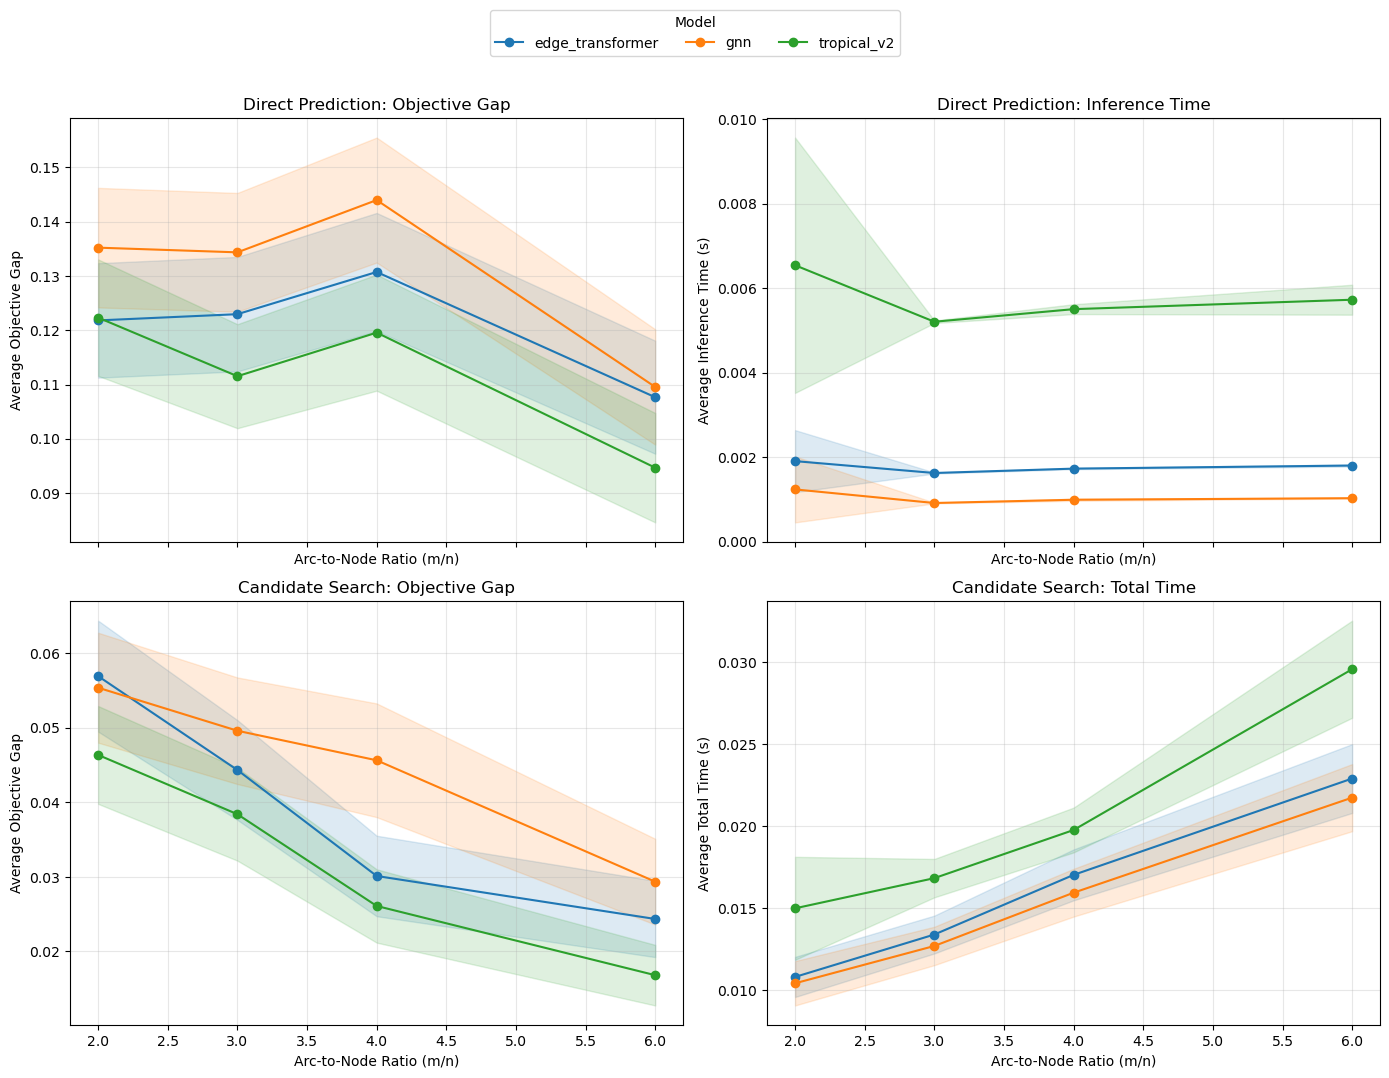

In [94]:
# create plots
plot_metrics_with_ci(summary)

## Unfiltered ID Filtered Evaluation

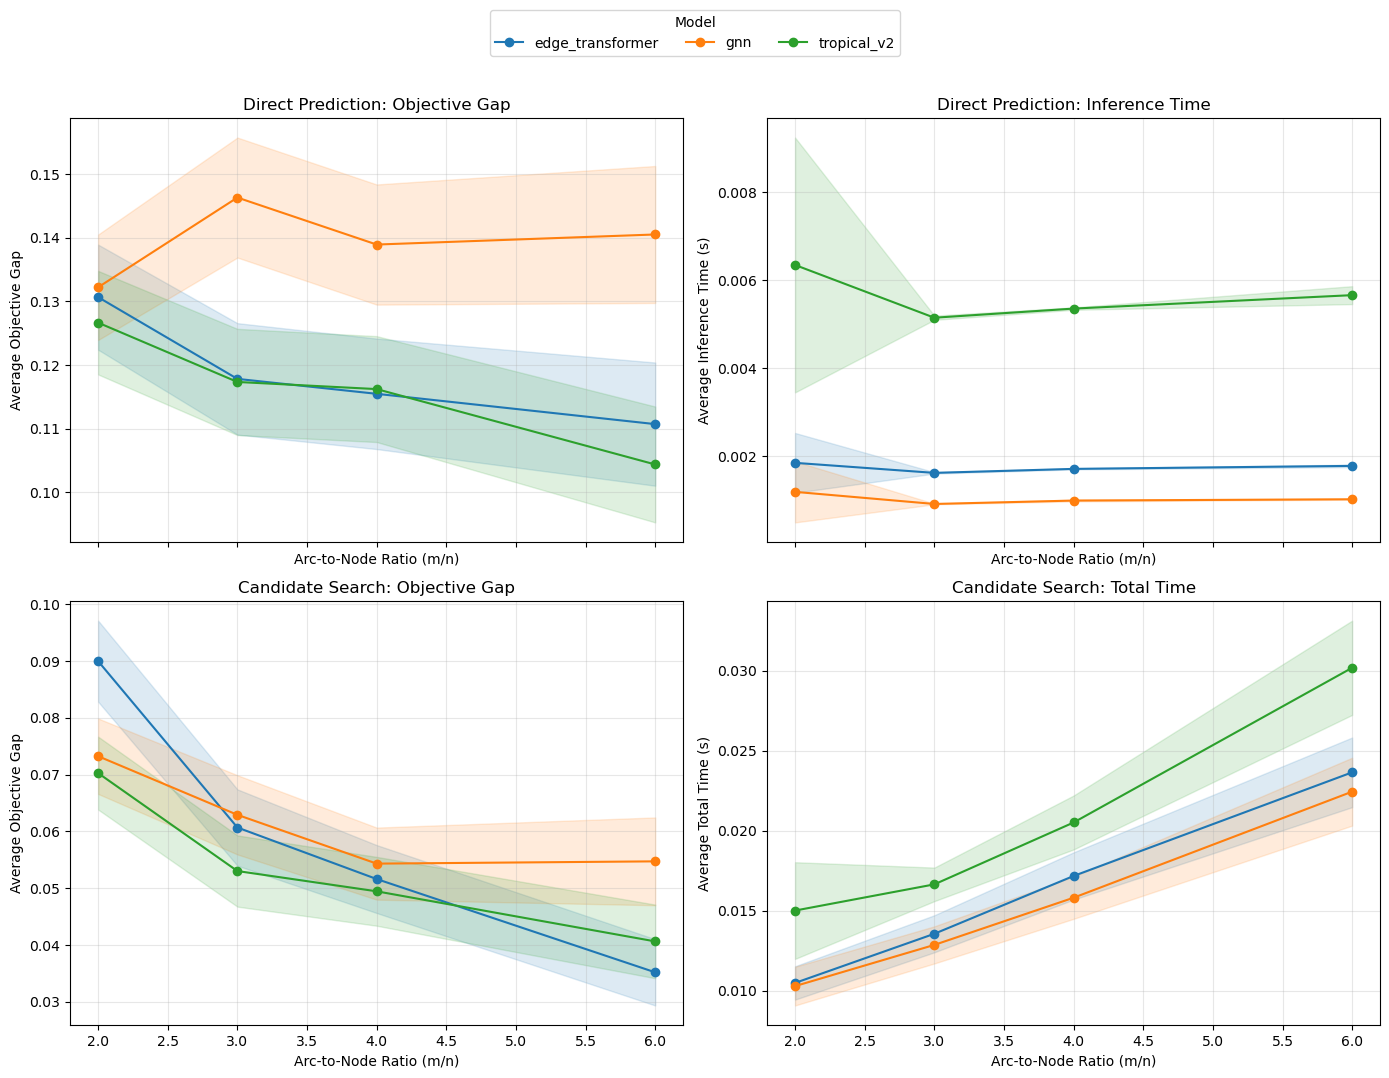

In [115]:
# create plots
plot_metrics_with_ci(summary)

## Unfiltered OOD Size Unfiltered Evaluation

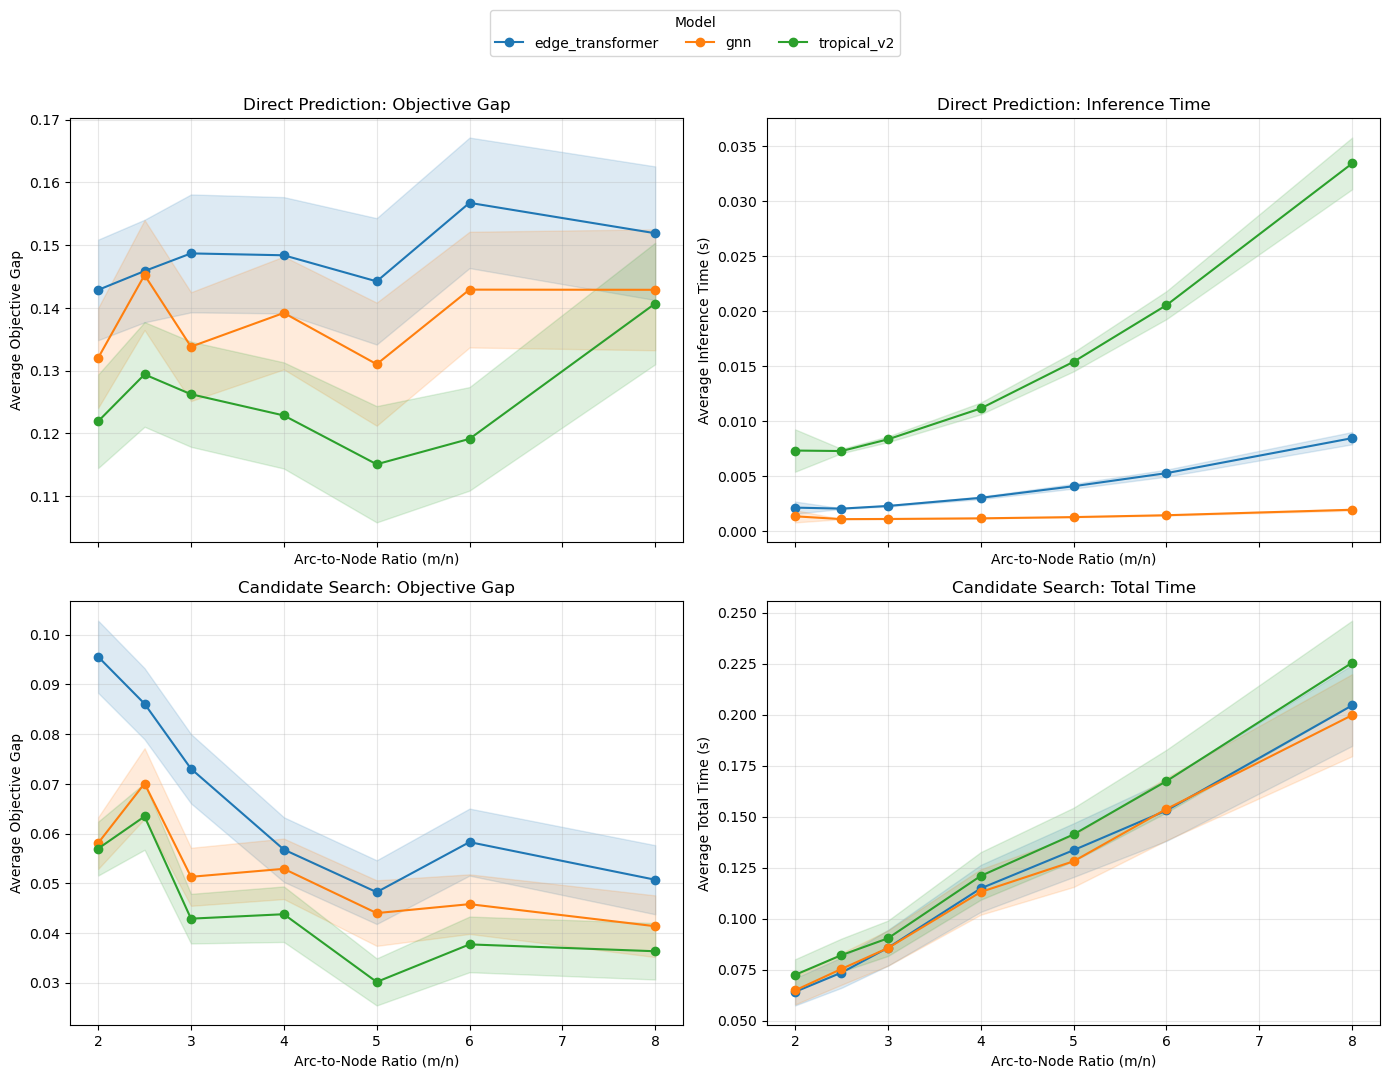

In [129]:
plot_metrics_with_ci(summary)

## Unfiltered OOD Size Filtered Evaluation

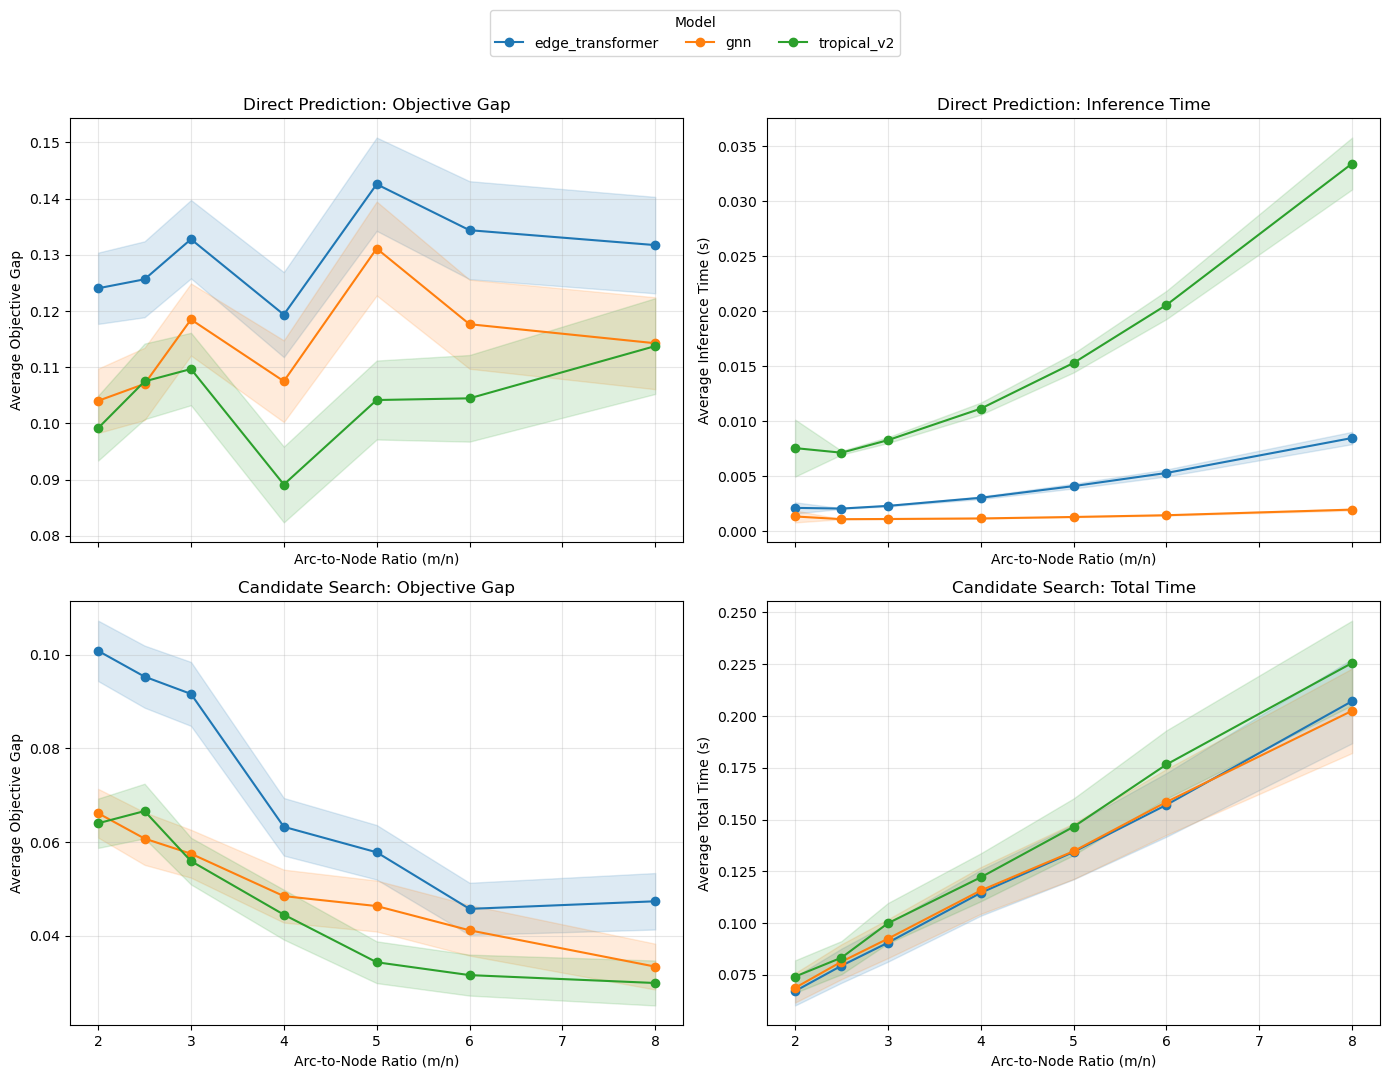

In [143]:
plot_metrics_with_ci(summary)

## Unfiltered OOD Value Unfiltered Evaluation

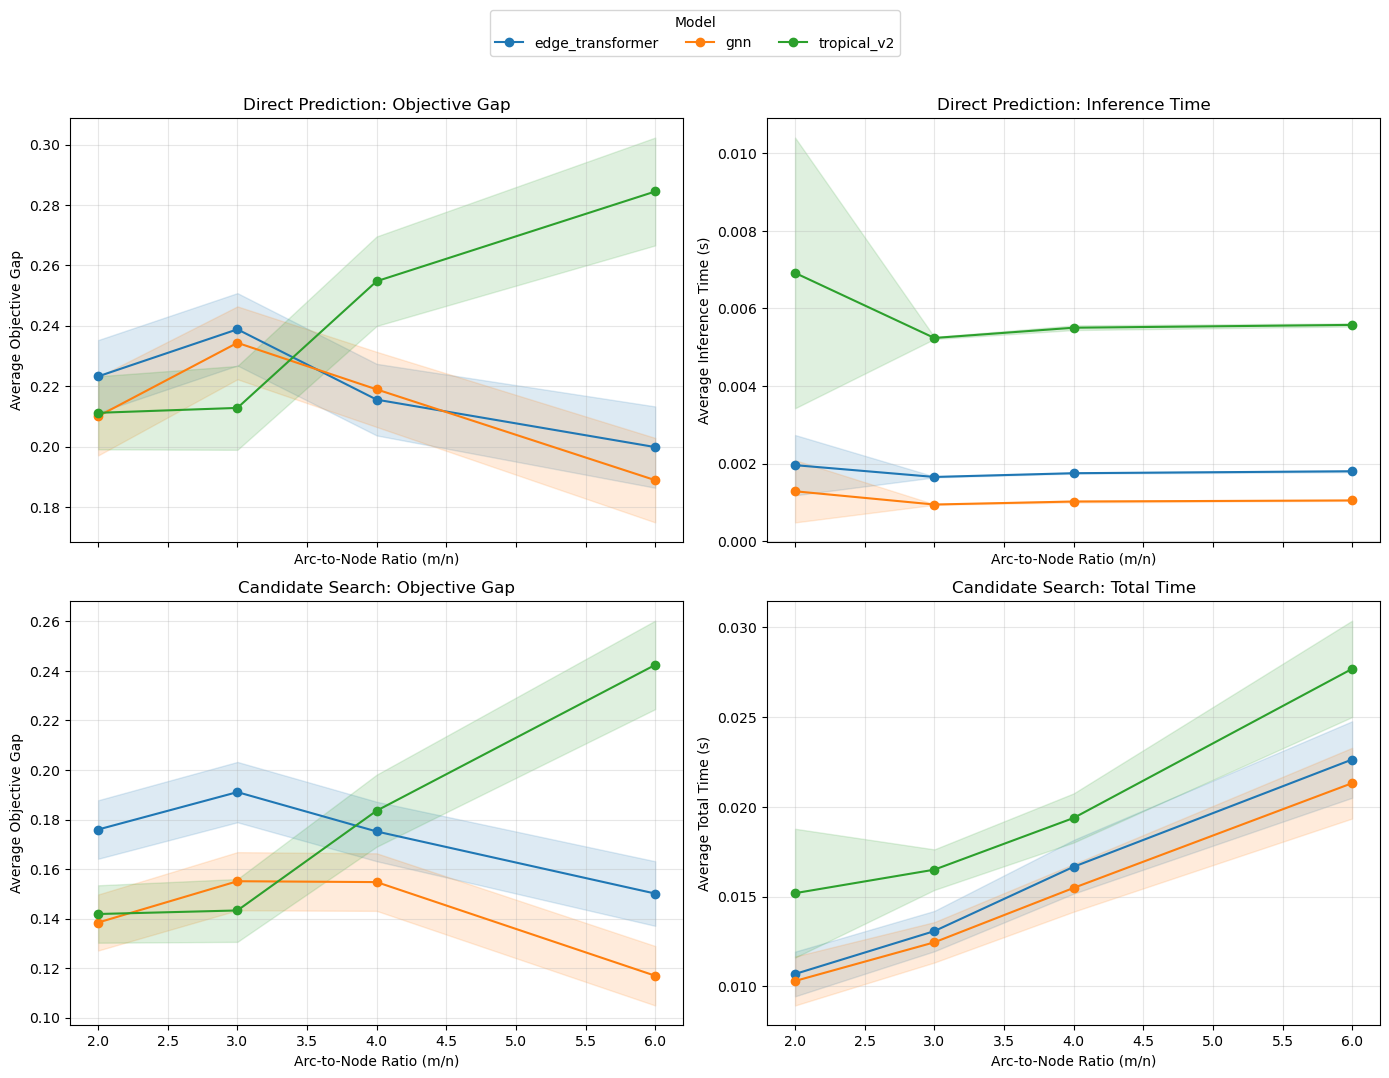

In [157]:
plot_metrics_with_ci(summary)

## Unfiltered OOD Value Filtered Evaluation

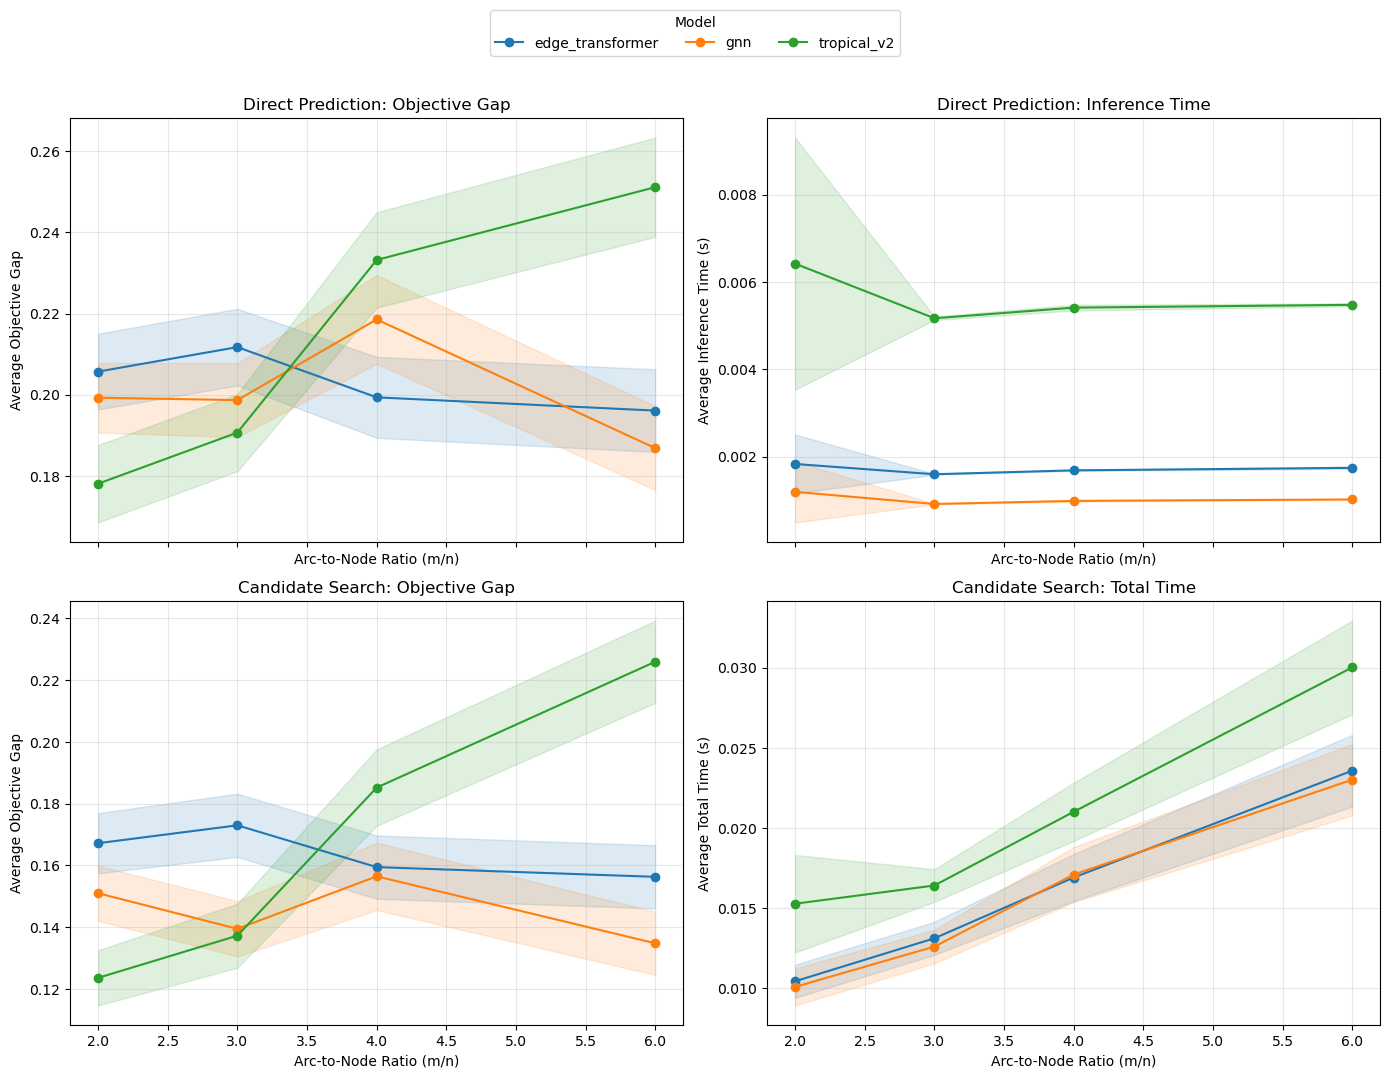

In [173]:
plot_metrics_with_ci(summary)

## Wood Evaluation

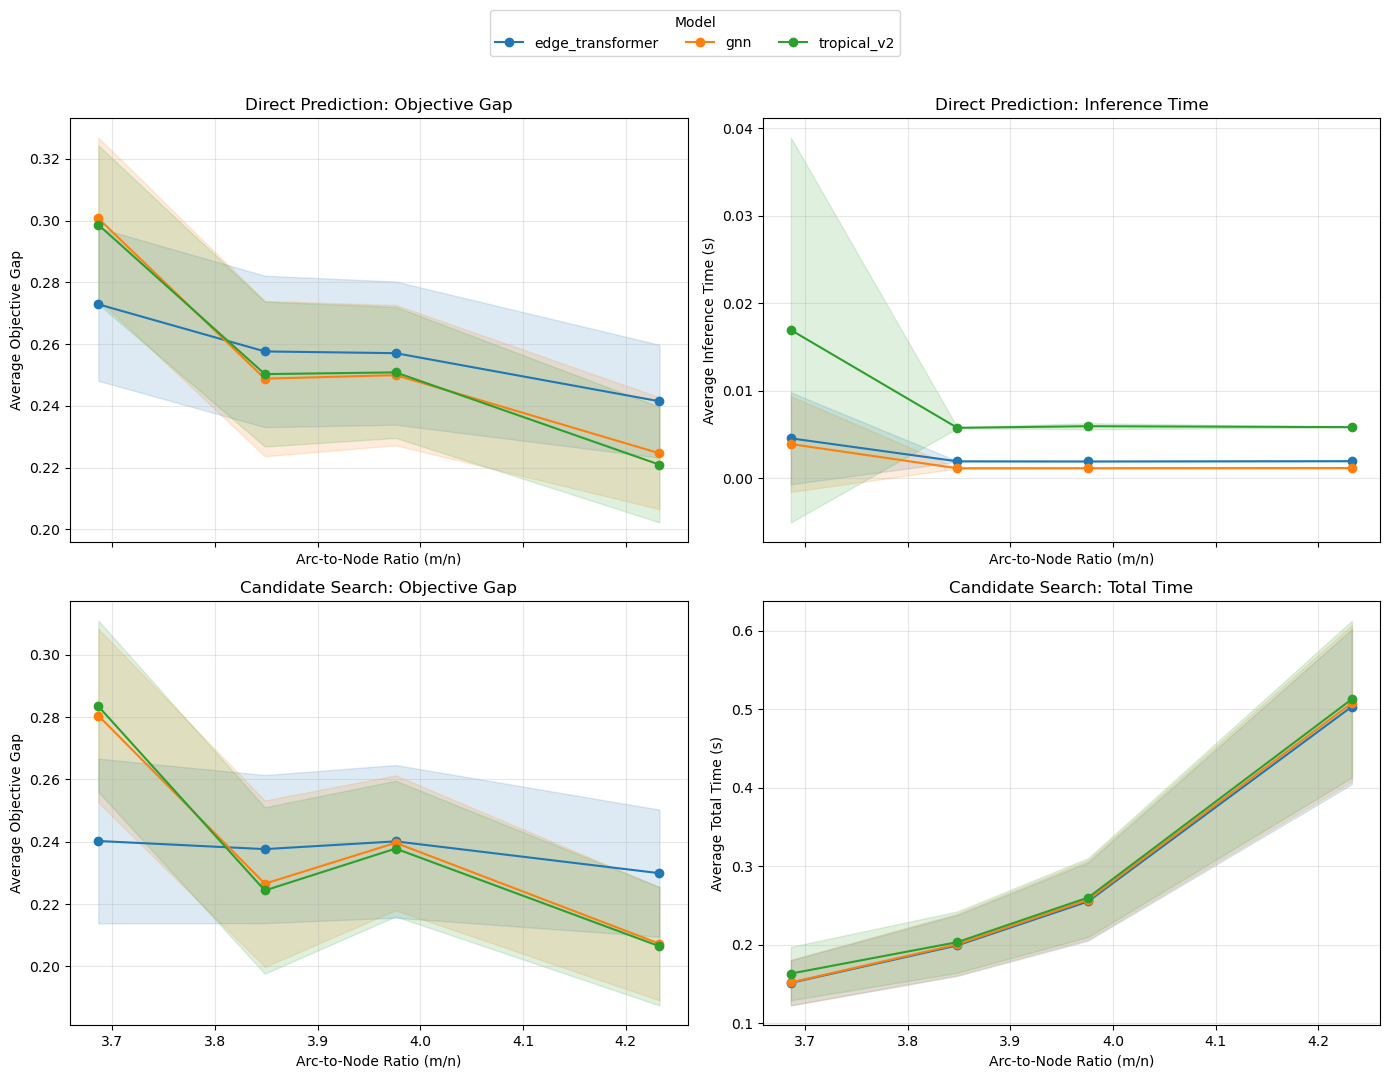

In [187]:
plot_metrics_with_ci(summary)

## External Evaluation

In [27]:
df_all_eval.head()

,model_type,problem_type,eval_mode,wood_problem,wood_rows,wood_cols,network_name,graph_seed,n_nodes,n_edges,density,replication,source,sink,source_original,sink_original,attack_limit,optimal_objective,predicted_objective,objective_gap,hamming_distance,exact_match,num_correct_edges,num_predicted_attacks,num_optimal_attacks,mip_solve_time,mip_total_time,inference_time,candidate_objective,candidate_objective_gap,candidate_pool_size,num_candidates,candidate_search_time,hybrid_total_time,candidate_exact_match,candidate_hamming_distance,candidate_correct_edges
0,gnn,shortest_path,external,NaN,NaN,NaN,rail_road_transportation_network,NaN,1054,3250,3.083491,NaN,0,5,1,6,1,789.978254,694.054024,0.121426,2,0,0,1,1,3.227064,3.403401,0.156491,694.054024,0.121426,5,5,0.041295,0.197785,0,2,0
1,gnn,shortest_path,external,NaN,NaN,NaN,rail_road_transportation_network,NaN,1054,3250,3.083491,NaN,0,6,1,7,1,280.083703,184.159473,0.342484,2,0,0,1,1,3.384331,3.582394,0.001922,184.159473,0.342484,5,5,0.025145,0.027067,0,2,0
2,gnn,shortest_path,external,NaN,NaN,NaN,rail_road_transportation_network,NaN,1054,3250,3.083491,NaN,0,7,1,8,1,255.830073,159.905843,0.374953,2,0,0,1,1,2.512488,2.702145,0.002145,159.905843,0.374953,5,5,0.025033,0.027178,0,2,0
3,gnn,shortest_path,external,NaN,NaN,NaN,rail_road_transportation_network,NaN,1054,3250,3.083491,NaN,0,8,1,9,1,256.580749,160.656519,0.373856,2,0,0,1,1,2.510386,2.735844,0.001944,160.656519,0.373856,5,5,0.024730,0.026674,0,2,0
4,gnn,shortest_path,external,NaN,NaN,NaN,rail_road_transportation_network,NaN,1054,3250,3.083491,NaN,0,974,1,1077,1,899.175041,803.250811,0.106680,2,0,0,1,1,3.774075,3.965521,0.002147,803.250811,0.106680,5,5,0.030175,0.032322,0,2,0


In [31]:
df_all_eval["od_pair"] = (
    df_all_eval["source_original"].astype(str)
    + " → "
    + df_all_eval["sink_original"].astype(str)
)

In [39]:
def plot_external_metrics_by_model(df, model):

    model_df = df[df["model_type"] == model].copy()

    metrics = [
        ("objective_gap",
         "Objective Gap",
         "Direct Prediction: Objective Gap"),

        ("inference_time",
         "Inference Time (s)",
         "Direct Prediction: Inference Time"),

        ("candidate_objective_gap",
         "Objective Gap",
         "Candidate Search: Objective Gap"),

        ("hybrid_total_time",
         "Total Time (s)",
         "Candidate Search: Total Time")]

    fig, axes = plt.subplots(2, 2, figsize=(18, 11), sharex=True)

    axes = axes.flatten()

    od_pairs = model_df["od_pair"].drop_duplicates().tolist()
    x_positions = np.arange(len(od_pairs))

    for ax, (metric, ylabel, title) in zip(axes, metrics):

        for k, group in model_df.groupby("attack_limit"):

            plot_data = (group.set_index("od_pair")[metric].reindex(od_pairs))

            ax.plot(x_positions, plot_data, marker="o", markersize=3, label=f"K={k}")

        ax.set_title(title)
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.3)

        ax.set_xticks(x_positions)
        ax.set_xticklabels(od_pairs, rotation=90, fontsize=8)

    fig.supxlabel("Source → Sink Pair")

    handles, labels = axes[0].get_legend_handles_labels()

    fig.legend(handles, labels, title="Interdiction Budget", loc="upper center", ncol=5, bbox_to_anchor=(0.5, 1.01))

    fig.suptitle(f"External Network Performance: {model}", y=1.05, fontsize=16)

    plt.tight_layout()
    plt.show()

In [33]:
external_summary = (
    df_all_eval
    .groupby(["model_type", "od_pair", "attack_limit"])
    .agg(

        count=("objective_gap", "count"),
        
        # Direct model prediction
        objective_gap_avg=("objective_gap", "mean"),
        objective_gap_median=("objective_gap", "median"),
        objective_gap_std=("objective_gap", "std"),

        candidate_objective_gap_avg=("candidate_objective_gap", "mean"),
        candidate_objective_gap_median=("candidate_objective_gap", "median"),
        candidate_objective_gap_std=("candidate_objective_gap", "std"),
        exact_match_avg=("exact_match", "mean"),
        exact_match_std=("exact_match", "std"),

        candidate_exact_match_avg=("candidate_exact_match", "mean"),
        candidate_exact_match_std=("candidate_exact_match", "std"),

        hamming_distance_avg=("hamming_distance", "mean"),
        hamming_distance_std=("hamming_distance", "std"),

        candidate_hamming_distance_avg=("candidate_hamming_distance", "mean"),
        candidate_hamming_distance_std=("candidate_hamming_distance", "std"),

        inference_time_avg=("inference_time", "mean"),
        inference_time_std=("inference_time", "std"),

        hybrid_total_time_avg=("hybrid_total_time", "mean"),
        hybrid_total_time_std=("hybrid_total_time", "std"),

        mip_solve_time_avg=("mip_solve_time", "mean"),
        mip_solve_time_std=("mip_solve_time", "std"),

        candidate_correct_edges_avg=("candidate_correct_edges", "mean"),
        candidate_correct_edges_std=("candidate_correct_edges", "std"),

        candidate_search_time_avg=("candidate_search_time", "mean"),
        candidate_search_time_std=("candidate_search_time", "std"),

        candidate_pool_size_avg=("candidate_pool_size", "mean"),
        num_candidates_avg=("num_candidates", "mean"),

    )
    .reset_index()
)

external_summary

,model_type,od_pair,attack_limit,count,objective_gap_avg,objective_gap_median,objective_gap_std,candidate_objective_gap_avg,candidate_objective_gap_median,candidate_objective_gap_std,exact_match_avg,exact_match_std,candidate_exact_match_avg,candidate_exact_match_std,hamming_distance_avg,hamming_distance_std,candidate_hamming_distance_avg,candidate_hamming_distance_std,inference_time_avg,inference_time_std,hybrid_total_time_avg,hybrid_total_time_std,mip_solve_time_avg,mip_solve_time_std,candidate_correct_edges_avg,candidate_correct_edges_std,candidate_search_time_avg,candidate_search_time_std,candidate_pool_size_avg,num_candidates_avg
0,edge_transformer,1 → 1077,1,1,0.106680,0.106680,NaN,0.106680,0.106680,NaN,0.0,NaN,0.0,NaN,2.0,NaN,2.0,NaN,0.010814,NaN,0.041157,NaN,3.773297,NaN,0.0,NaN,0.030343,NaN,5.0,5.0
1,edge_transformer,1 → 1077,2,1,0.148327,0.148327,NaN,0.148327,0.148327,NaN,0.0,NaN,0.0,NaN,4.0,NaN,4.0,NaN,0.010710,NaN,0.243993,NaN,6.792475,NaN,0.0,NaN,0.233283,NaN,6.0,15.0
2,edge_transformer,1 → 1077,3,1,0.169649,0.169649,NaN,0.141316,0.141316,NaN,0.0,NaN,0.0,NaN,6.0,NaN,6.0,NaN,0.010694,NaN,0.213425,NaN,16.521233,NaN,0.0,NaN,0.202731,NaN,7.0,35.0
3,edge_transformer,1 → 1077,4,1,0.189823,0.189823,NaN,0.162179,0.162179,NaN,0.0,NaN,0.0,NaN,8.0,NaN,8.0,NaN,0.010713,NaN,0.545306,NaN,26.549647,NaN,0.0,NaN,0.534593,NaN,8.0,70.0
4,edge_transformer,1 → 1077,5,1,0.218030,0.218030,NaN,0.191349,0.191349,NaN,0.0,NaN,0.0,NaN,10.0,NaN,10.0,NaN,0.010795,NaN,0.950721,NaN,31.097552,NaN,0.0,NaN,0.939926,NaN,9.0,126.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
595,tropical_v2,5 → 9,1,1,0.594858,0.594858,NaN,0.594858,0.594858,NaN,0.0,NaN,0.0,NaN,2.0,NaN,2.0,NaN,0.038839,NaN,0.060650,NaN,2.989667,NaN,0.0,NaN,0.021811,NaN,5.0,5.0
596,tropical_v2,5 → 9,2,1,0.745970,0.745970,NaN,0.745970,0.745970,NaN,0.0,NaN,0.0,NaN,4.0,NaN,4.0,NaN,0.038733,NaN,0.219201,NaN,2.066374,NaN,0.0,NaN,0.180468,NaN,6.0,15.0
597,tropical_v2,5 → 9,3,1,0.770779,0.770779,NaN,0.770779,0.770779,NaN,0.0,NaN,0.0,NaN,6.0,NaN,6.0,NaN,0.038786,NaN,0.187204,NaN,2.456785,NaN,0.0,NaN,0.148418,NaN,7.0,35.0
598,tropical_v2,5 → 9,4,1,0.786025,0.786025,NaN,0.786025,0.786025,NaN,0.0,NaN,0.0,NaN,8.0,NaN,8.0,NaN,0.038732,NaN,0.450345,NaN,3.225718,NaN,0.0,NaN,0.411614,NaN,8.0,70.0


In [55]:
external = external_summary.sort_values(by='objective_gap_avg', ascending=False)
external.head(30)

,model_type,od_pair,attack_limit,count,objective_gap_avg,objective_gap_median,objective_gap_std,candidate_objective_gap_avg,candidate_objective_gap_median,candidate_objective_gap_std,exact_match_avg,exact_match_std,candidate_exact_match_avg,candidate_exact_match_std,hamming_distance_avg,hamming_distance_std,candidate_hamming_distance_avg,candidate_hamming_distance_std,inference_time_avg,inference_time_std,hybrid_total_time_avg,hybrid_total_time_std,mip_solve_time_avg,mip_solve_time_std,candidate_correct_edges_avg,candidate_correct_edges_std,candidate_search_time_avg,candidate_search_time_std,candidate_pool_size_avg,num_candidates_avg
264,gnn,4 → 7,5,1,0.878047,0.878047,NaN,0.878047,0.878047,NaN,0.0,NaN,0.0,NaN,10.0,NaN,10.0,NaN,0.001934,NaN,0.729956,NaN,2.720907,NaN,0.0,NaN,0.728022,NaN,9.0,126.0
564,tropical_v2,4 → 7,5,1,0.878047,0.878047,NaN,0.878047,0.878047,NaN,0.0,NaN,0.0,NaN,10.0,NaN,10.0,NaN,0.038802,NaN,0.699226,NaN,2.826341,NaN,0.0,NaN,0.660423,NaN,9.0,126.0
114,edge_transformer,4 → 7,5,1,0.878047,0.878047,NaN,0.878047,0.878047,NaN,0.0,NaN,0.0,NaN,10.0,NaN,10.0,NaN,0.010563,NaN,0.733929,NaN,2.724841,NaN,0.0,NaN,0.723366,NaN,9.0,126.0
414,tropical,4 → 7,5,1,0.878047,0.878047,NaN,0.675308,0.675308,NaN,0.0,NaN,0.0,NaN,10.0,NaN,8.0,NaN,0.119199,NaN,0.852702,NaN,2.723115,NaN,1.0,NaN,0.733502,NaN,9.0,126.0
263,gnn,4 → 7,4,1,0.862220,0.862220,NaN,0.862220,0.862220,NaN,0.0,NaN,0.0,NaN,8.0,NaN,8.0,NaN,0.001930,NaN,0.408943,NaN,2.194325,NaN,0.0,NaN,0.407013,NaN,8.0,70.0
563,tropical_v2,4 → 7,4,1,0.862220,0.862220,NaN,0.862220,0.862220,NaN,0.0,NaN,0.0,NaN,8.0,NaN,8.0,NaN,0.038823,NaN,0.458025,NaN,2.183329,NaN,0.0,NaN,0.419202,NaN,8.0,70.0
113,edge_transformer,4 → 7,4,1,0.862220,0.862220,NaN,0.862220,0.862220,NaN,0.0,NaN,0.0,NaN,8.0,NaN,8.0,NaN,0.010625,NaN,0.412338,NaN,2.192087,NaN,0.0,NaN,0.401713,NaN,8.0,70.0
413,tropical,4 → 7,4,1,0.862220,0.862220,NaN,0.633171,0.633171,NaN,0.0,NaN,0.0,NaN,8.0,NaN,6.0,NaN,0.118991,NaN,0.524736,NaN,2.193121,NaN,1.0,NaN,0.405745,NaN,8.0,70.0
262,gnn,4 → 7,3,1,0.832979,0.832979,NaN,0.832979,0.832979,NaN,0.0,NaN,0.0,NaN,6.0,NaN,6.0,NaN,0.001926,NaN,0.151624,NaN,2.433366,NaN,0.0,NaN,0.149698,NaN,7.0,35.0
562,tropical_v2,4 → 7,3,1,0.832979,0.832979,NaN,0.832979,0.832979,NaN,0.0,NaN,0.0,NaN,6.0,NaN,6.0,NaN,0.039063,NaN,0.188959,NaN,2.537765,NaN,0.0,NaN,0.149896,NaN,7.0,35.0


In [278]:
metrics_for_ci = [
    "objective_gap",
    "candidate_objective_gap",
    "inference_time",
    "hybrid_total_time"
]

summary = add_confidence_intervals(external_summary, metrics_for_ci)

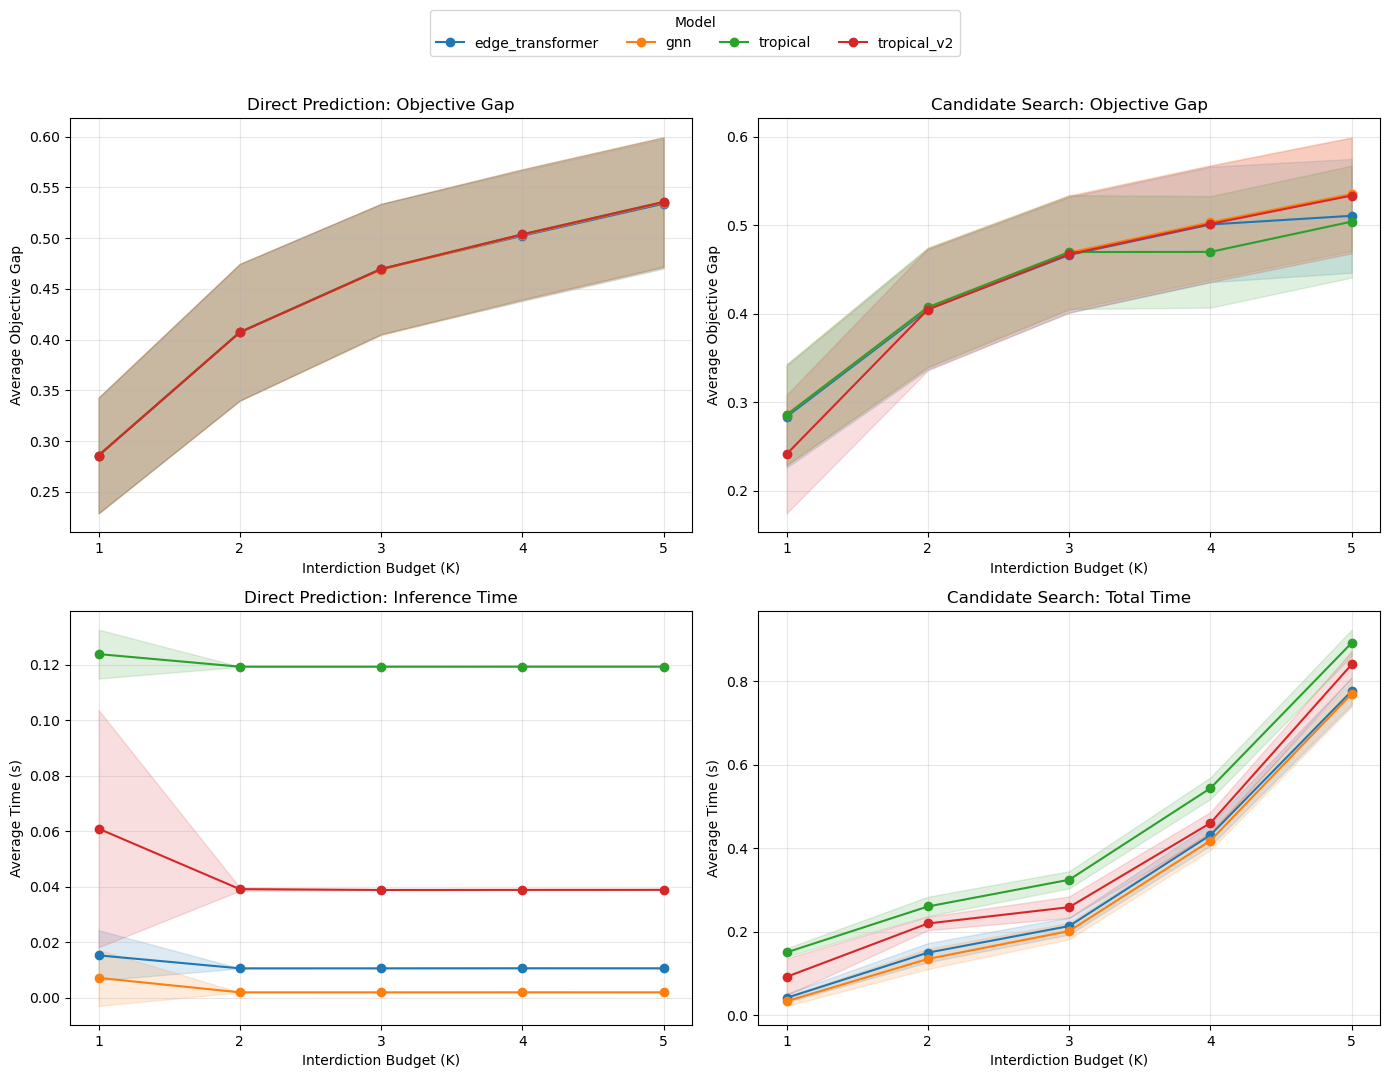

In [280]:
plot_external_metrics(summary)

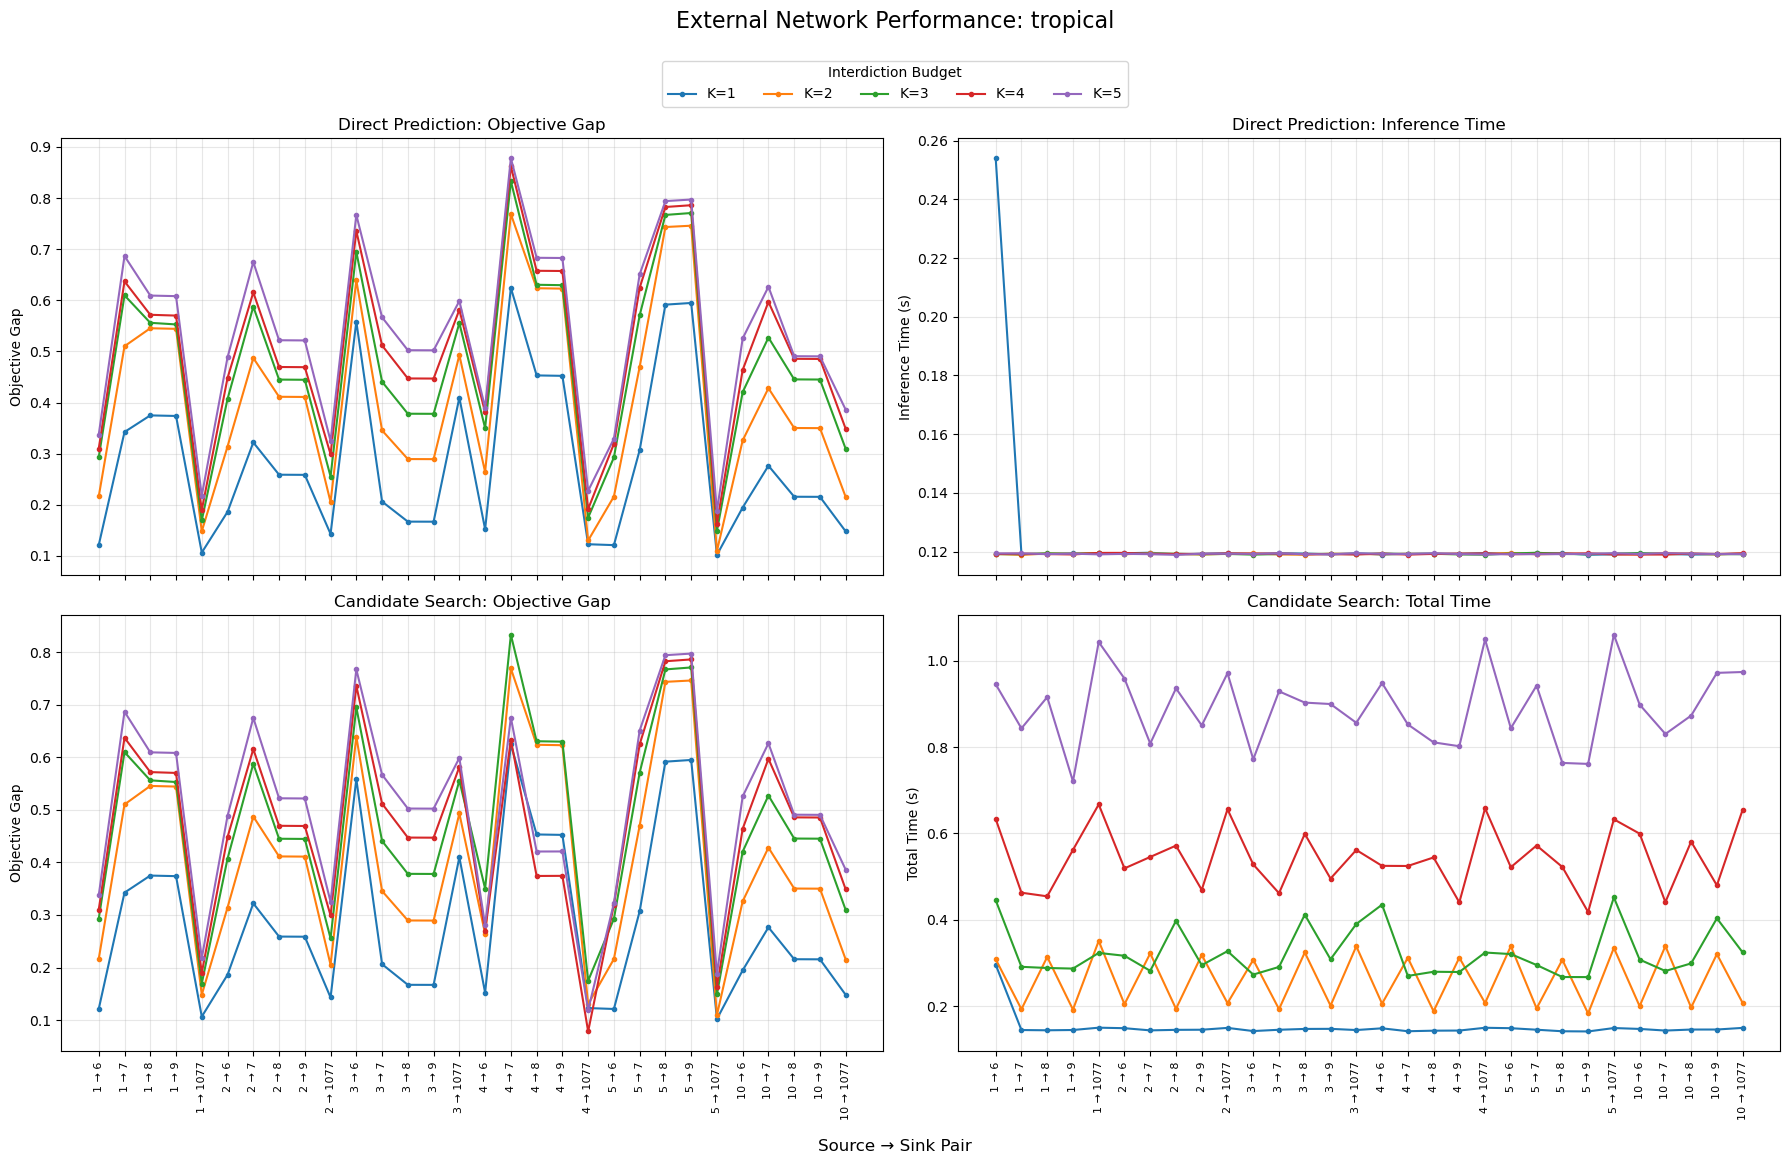

In [43]:
plot_external_metrics_by_model(df_all_eval, "tropical")

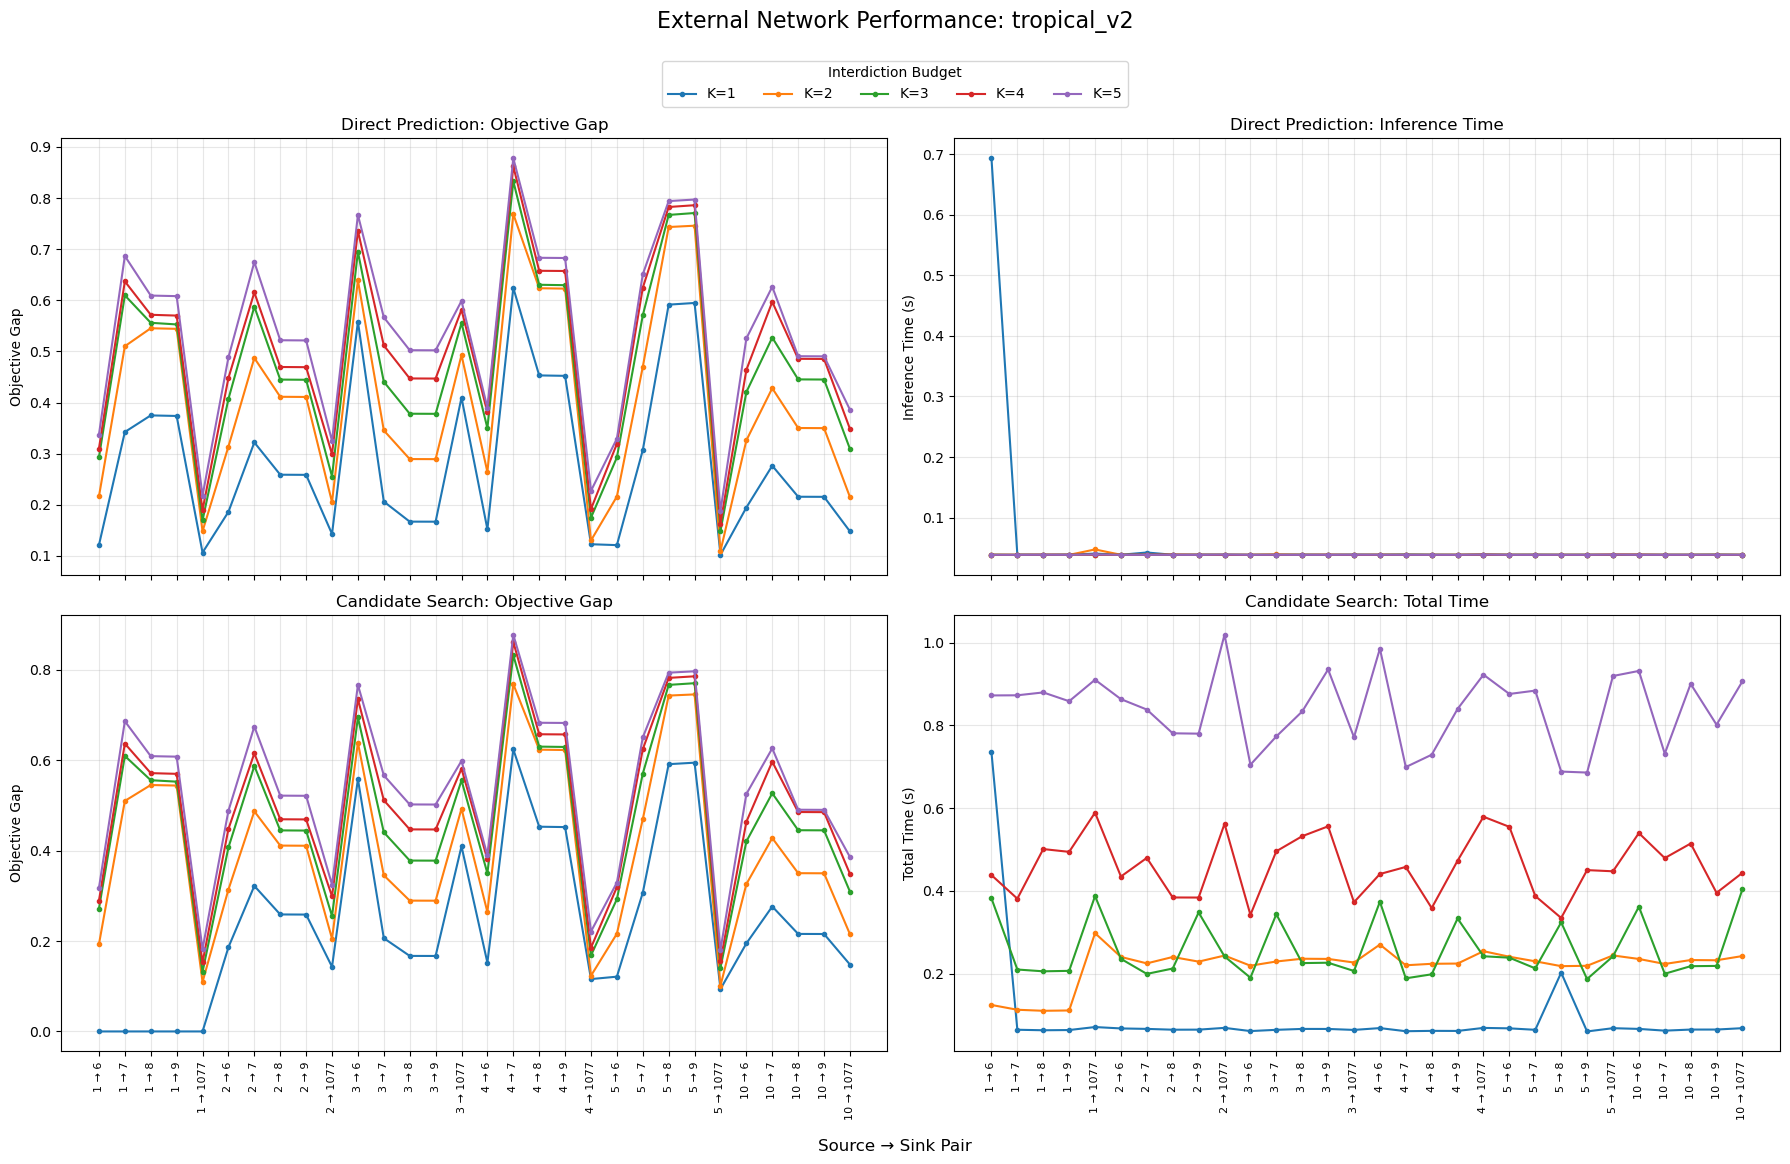

In [45]:
plot_external_metrics_by_model(df_all_eval, "tropical_v2")

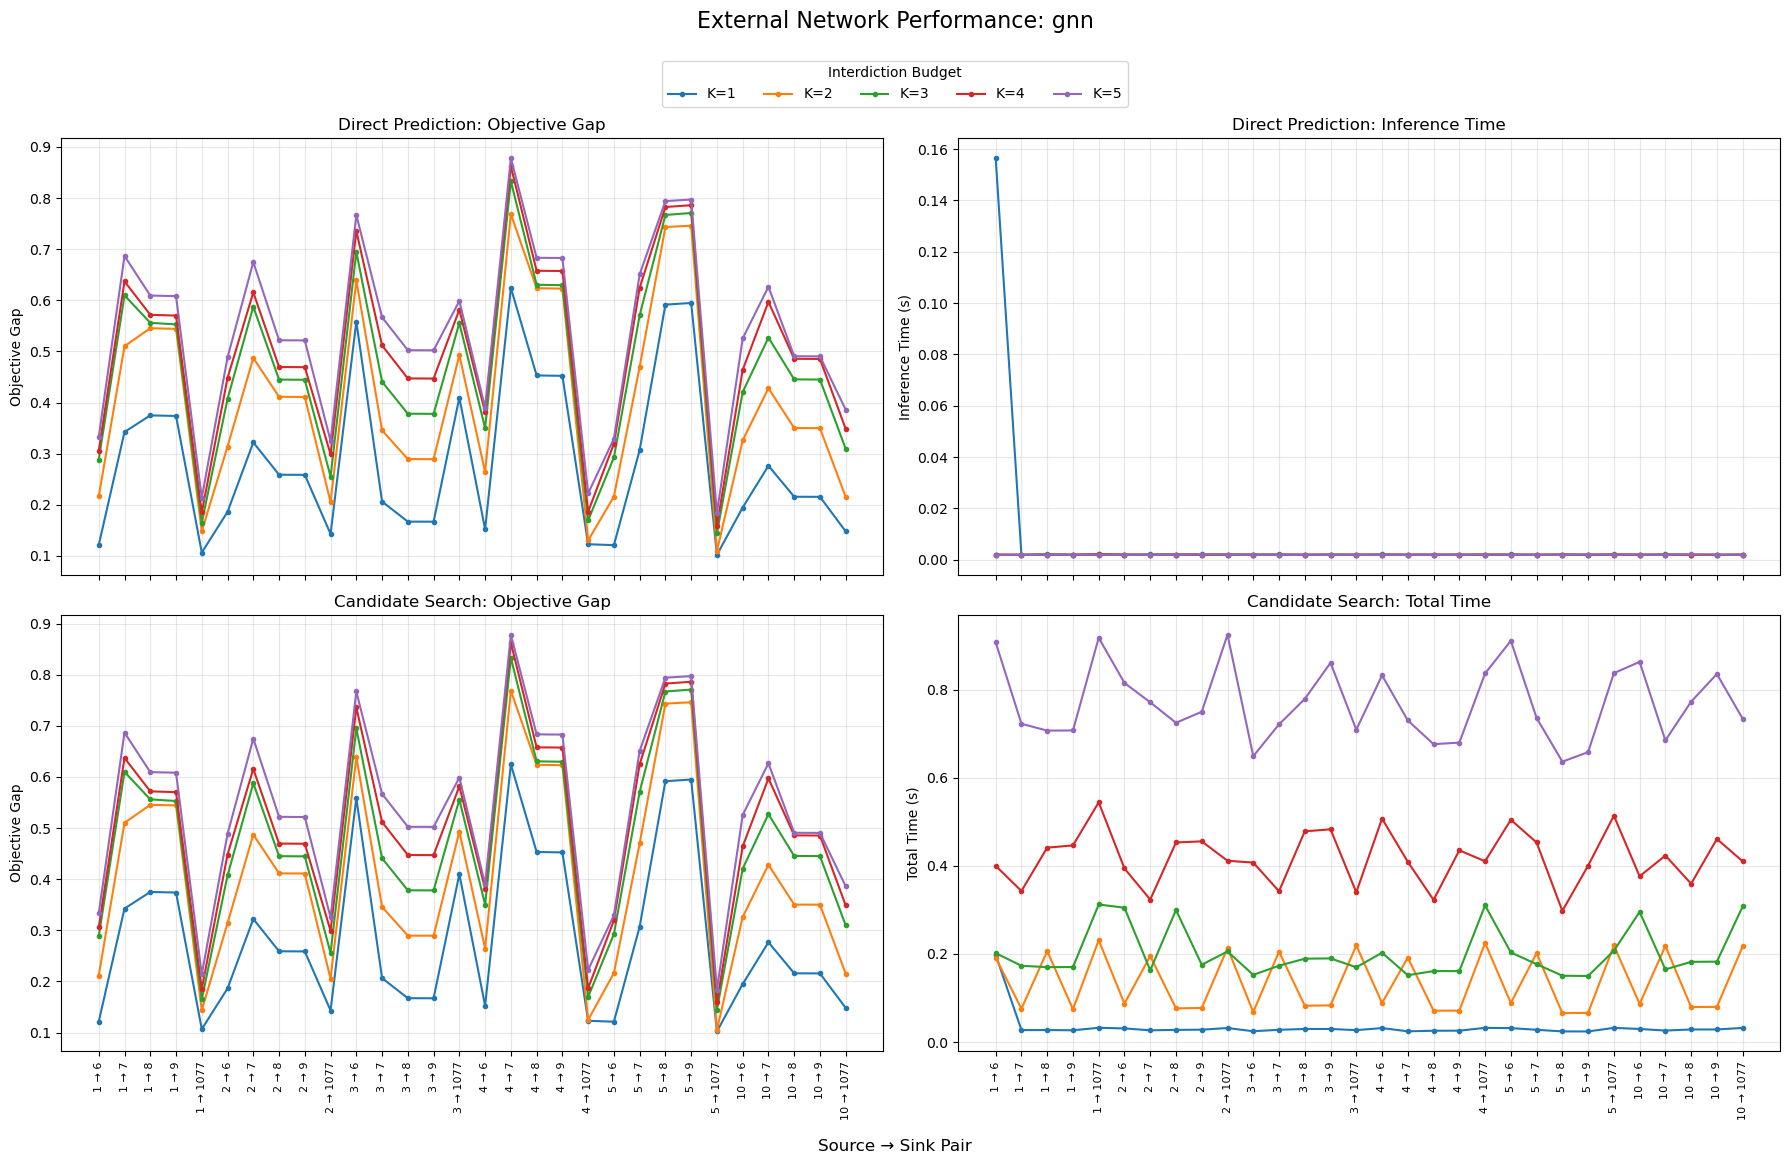

In [47]:
plot_external_metrics_by_model(df_all_eval, "gnn")

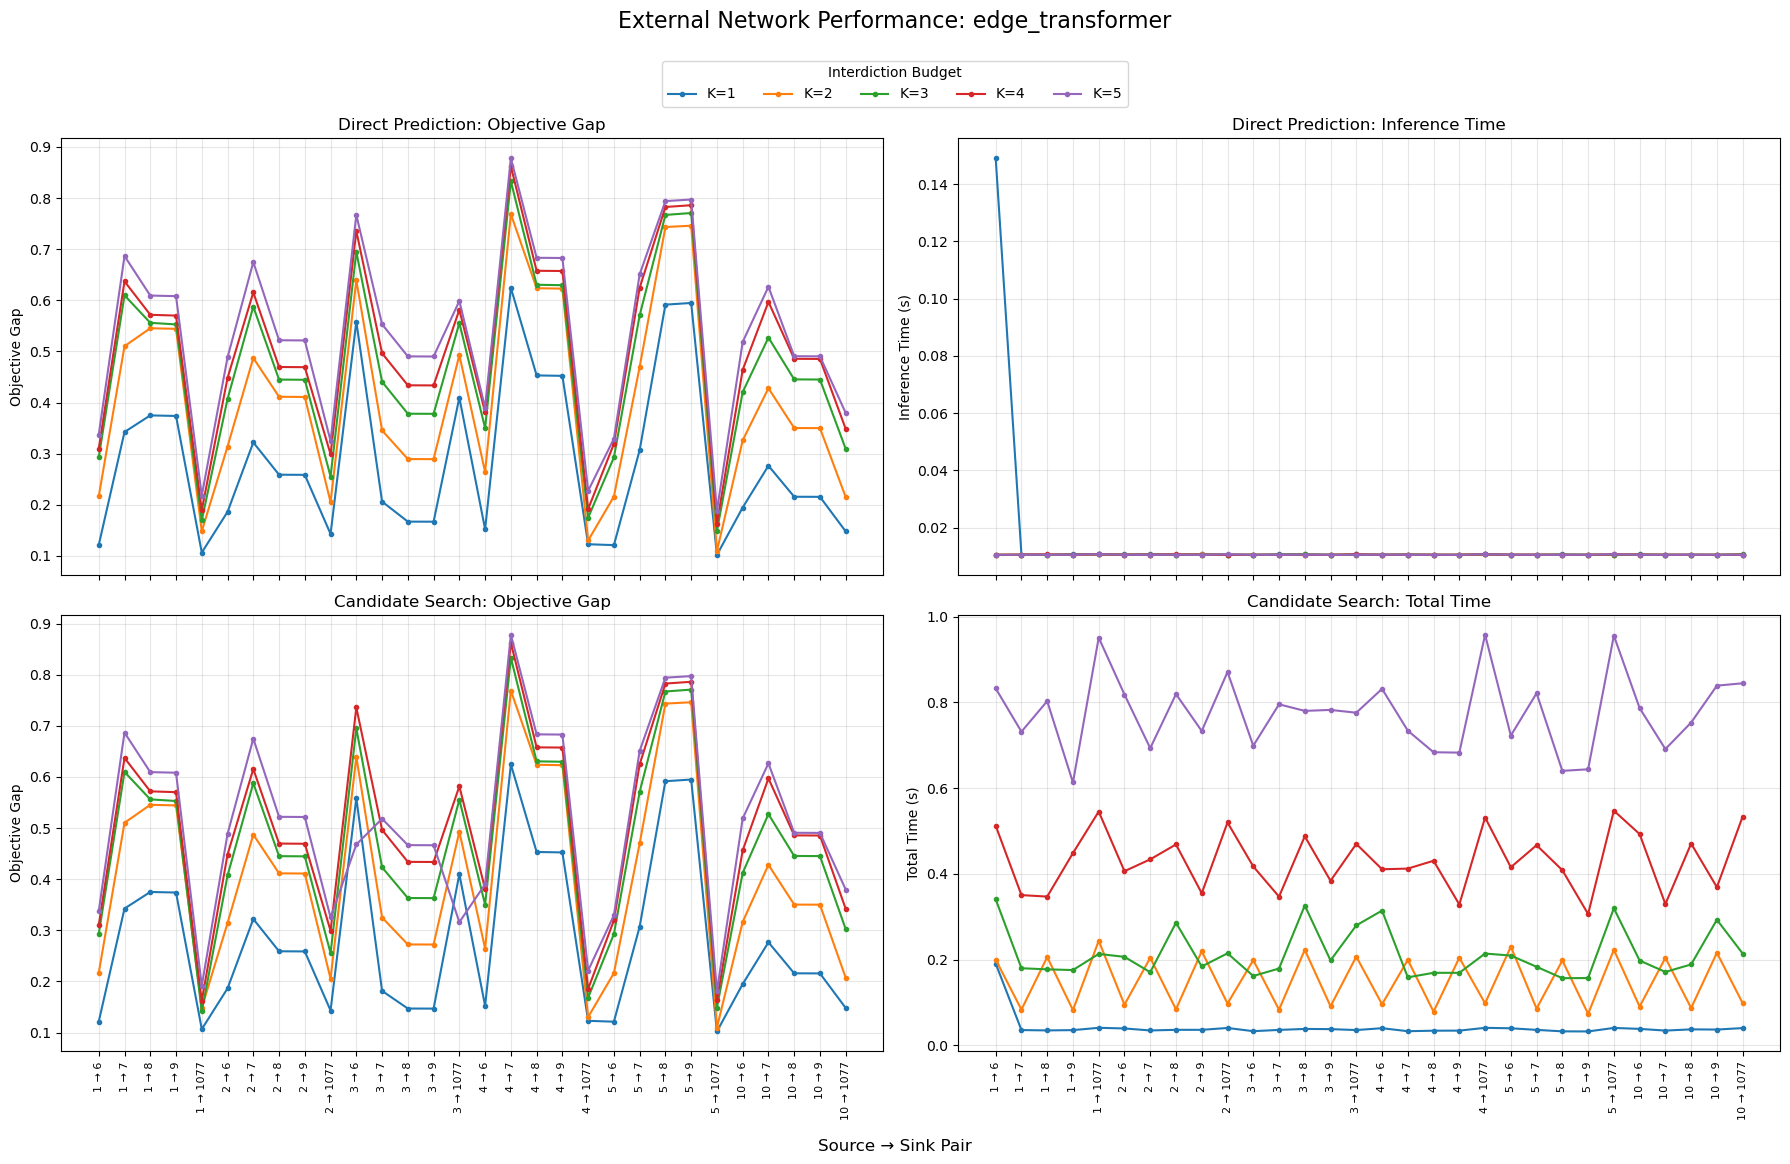

In [49]:
plot_external_metrics_by_model(df_all_eval, "edge_transformer")